# Сравнение символьных GPT с контекстом 64 и 128 на стихах Пушкина

**Лабораторная работа по исследованию архитектуры Transformer (nanoGPT А. Карпати)**  
**Цель работы:** Сравнить две конфигурации символьной языковой модели nanoGPT с длиной контекста 64 и 128 (`block_size = 64` vs `block_size = 128`) при обучении в течение 5000 шагов на русскоязычном стихотворном корпусе А. С. Пушкина. Исследование выполнено по 3 независимым случайным сидам (`SEEDS = [42, 1337, 2026]`) для оценки статистической устойчивости результатов и выявления признаков переобучения.

### Параметры эксперимента (ТЗ Ступакова):
- `batch_size`: 32
- `block_size`: 64 vs 128
- `max_iters`: 5000
- `eval_interval`: 500
- `eval_iters`: 20
- `learning_rate`: 3e-4
- `n_embd`: 384
- `n_head`: 4
- `n_layer`: 2
- `dropout`: 0.1
- Оптимизатор: AdamW

In [1]:
import hashlib
import json
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display

from gpt import (
    GPTConfig,
    GPTLanguageModel,
    get_device,
    load_corpus,
    get_batch,
    estimate_loss,
    evaluate_fixed_targets,
    validate_prompt,
    save_checkpoint,
    load_checkpoint,
    run_microbenchmark,
    train_single_model,
    generate_samples_for_prompts,
)

MASTER_SEED = 1337
torch.manual_seed(MASTER_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MASTER_SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = get_device()
print(f"PyTorch version: {torch.__version__}")
print(f"Устройство: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
if torch.cuda.is_available():
    print(f"Версия CUDA: {torch.version.cuda}")
    print(f"Доступная VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

PyTorch version: 2.5.1+cu121
Устройство: cuda (NVIDIA GeForce GTX 1050)
Версия CUDA: 12.1
Доступная VRAM: 4.00 GB


## 1. Загрузка и подготовка корпуса

Обучение проводится на стихотворениях А. С. Пушкина (`input.txt`). Фиксируется контрольная сумма SHA-256 для воспроизводимости. Для честного сопоставления моделей с разной длиной контекста заранее зафиксированы по 2000 позиций в валидационной и обучающей выборках с предшествующим контекстом $\ge 128$ символов.

In [2]:
corpus = load_corpus("input.txt", encoding="utf-8", train_ratio=0.9)

print(f"Файл корпуса: input.txt")
print(f"Размер в байтах: {corpus['raw_bytes']:,} байт ({corpus['raw_bytes']/1024:.1f} КБ)")
print(f"Всего символов: {len(corpus['text']):,}")
print(f"SHA-256 корпуса: {corpus['sha256']}")
print(f"Размер словаря (vocab_size): {corpus['vocab_size']}")
print(f"Train выборка: {len(corpus['train_data']):,} символов (90.0%)")
print(f"Val выборка:   {len(corpus['val_data']):,} символов (10.0%)")

# Фиксируем 2000 позиций валидации и 2000 позиций обучения (контекст >= 128)
val_len = len(corpus["val_data"])
train_len = len(corpus["train_data"])
idx_rng = np.random.RandomState(42)

results_dir = Path("results/pushkin_seeds")
results_dir.mkdir(parents=True, exist_ok=True)
idx_path = results_dir / "fixed_target_indices.json"

if idx_path.exists():
    with open(idx_path, "r", encoding="utf-8") as f:
        saved_indices = json.load(f)
    fixed_val_targets = saved_indices["val"]
    fixed_train_targets = saved_indices["train"]
else:
    fixed_val_targets = sorted(idx_rng.choice(np.arange(128, val_len), size=2000, replace=False).tolist())
    fixed_train_targets = sorted(idx_rng.choice(np.arange(128, train_len), size=2000, replace=False).tolist())
    with open(idx_path, "w", encoding="utf-8") as f:
        json.dump({"val": fixed_val_targets, "train": fixed_train_targets}, f)

print(f"Зафиксировано {len(fixed_val_targets)} позиций валидации и {len(fixed_train_targets)} позиций обучения.")

Файл корпуса: input.txt
Размер в байтах: 973,655 байт (950.8 КБ)
Всего символов: 546,532
SHA-256 корпуса: 5e03933aaae8fcd12a30f5afde8945678f2771a70a2fa95bc9ac2c84b263cc52
Размер словаря (vocab_size): 133
Train выборка: 491,878 символов (90.0%)
Val выборка:   54,654 символов (10.0%)
Зафиксировано 2000 позиций валидации и 2000 позиций обучения.


## 2. Конфигурация моделей

Все гиперпараметры архитектуры идентичны, за исключением длины контекста:
- Базовая конфигурация: `block_size = 64`
- Конфигурация с расширенным контекстом: `block_size = 128`
- Разница параметров составляет ровно $+24\,576$ весов ($+0.67\%$) за счет таблицы позиционных эмбеддингов ($(128 - 64) \times 384$).

In [3]:
COMMON_CONFIG = {
    "vocab_size": corpus["vocab_size"],
    "batch_size": 32,
    "max_iters": 5000,
    "eval_interval": 500,
    "eval_iters": 20,
    "learning_rate": 3e-4,
    "n_embd": 384,
    "n_head": 4,
    "n_layer": 2,
    "dropout": 0.1,
    "device": device,
}

CONFIG_64 = GPTConfig(**dict(COMMON_CONFIG, block_size=64))
CONFIG_128 = GPTConfig(**dict(COMMON_CONFIG, block_size=128))

m64_tmp = GPTLanguageModel(config=CONFIG_64)
m128_tmp = GPTLanguageModel(config=CONFIG_128)
p64 = sum(p.numel() for p in m64_tmp.parameters())
p128 = sum(p.numel() for p in m128_tmp.parameters())
delta_p = p128 - p64

print(f"Параметров в модели 64:  {p64:,}")
print(f"Параметров в модели 128: {p128:,}")
print(f"Разница в параметрах: +{delta_p:,} (+{delta_p / p64 * 100:.2f}%) за счет таблицы позиционных эмбеддингов ((128-64)*384)")
del m64_tmp, m128_tmp

Параметров в модели 64:  3,674,245


Параметров в модели 128: 3,698,821
Разница в параметрах: +24,576 (+0.67%) за счет таблицы позиционных эмбеддингов ((128-64)*384)


## 3. Обучение моделей по трем сидам (6 запусков)

Для проверки воспроизводимости обе модели обучены на трех случайных сидах (`SEEDS = [42, 1337, 2026]`) по 5000 шагов каждая.
При `FORCE_RETRAIN = False` загружаются уже сохраненные чекпоинты и траектории из `results/pushkin_seeds/`.

In [4]:
SEEDS = [42, 1337, 2026]
BLOCK_SIZES = [64, 128]
FORCE_RETRAIN = False

summary_file = results_dir / "summary_all_runs.csv"
history_file = results_dir / "loss_trajectories.csv"

RUN_PLAN = [
    (42, 64),
    (42, 128),
    (1337, 128),
    (1337, 64),
    (2026, 64),
    (2026, 128),
]

all_checkpoints_exist = (
    summary_file.exists()
    and history_file.exists()
    and all(
        (results_dir / f"checkpoint_{bs}_seed{s}_final.pt").exists()
        and (results_dir / f"checkpoint_{bs}_seed{s}_best.pt").exists()
        for s in SEEDS for bs in BLOCK_SIZES
    )
)

if not FORCE_RETRAIN and all_checkpoints_exist:
    print("Загрузка результатов 6 выполненных сессий обучения...")
    summary_df = pd.read_csv(summary_file)
    trajectories_df = pd.read_csv(history_file)
    print("Все результаты и траектории успешно загружены.")
else:
    print("Запуск 6 сессий обучения по 5000 шагов...")
    all_runs = []
    all_trajectories = []

    for seed, bs in RUN_PLAN:
        cfg = CONFIG_64 if bs == 64 else CONFIG_128
        run_res = train_single_model(
            config=cfg,
            corpus=corpus,
            seed=seed,
            fixed_val_targets=fixed_val_targets,
            fixed_train_targets=fixed_train_targets,
            save_dir=results_dir,
            verbose=True,
        )

        row = {
            "seed": seed,
            "block_size": bs,
            "max_iters": run_res["max_iters"],
            "processed_tokens": run_res["processed_tokens"],
            "pure_train_sec": round(run_res["pure_training_seconds"], 2),
            "total_sec": round(run_res["total_experiment_seconds"], 2),
            "ms_per_step": round(run_res["ms_per_step"], 2),
            "tokens_per_sec": round(run_res["throughput_chars_per_sec"], 1),
            "final_train_nll": round(run_res["final_train_nll_comp"], 4),
            "final_val_nll": round(run_res["final_val_nll_comp"], 4),
            "best_val_nll": round(run_res["best_val_nll_comp"], 4),
            "best_step": run_res["best_step"],
            "nll_degradation": round(run_res["nll_degradation"], 4),
            "val_nll_at_2500": round(run_res["val_nll_at_2500"], 4) if run_res["val_nll_at_2500"] is not None else None,
        }
        all_runs.append(row)

        for h in run_res["history"]:
            h_entry = dict(h, seed=seed, block_size=bs)
            all_trajectories.append(h_entry)

    summary_df = pd.DataFrame(all_runs)
    summary_df.to_csv(summary_file, index=False)

    trajectories_df = pd.DataFrame(all_trajectories)
    trajectories_df.to_csv(history_file, index=False)
    print("Все 6 сессий обучения завершены.")

Загрузка результатов 6 выполненных сессий обучения...
Все результаты и траектории успешно загружены.


## 4. Результаты и анализ динамики обучения

Сравнение моделей по сопоставимому Validation NLL, чистому времени оптимизации и скорости выполнения шага на трех независимых сидах (`ddof=1`).

In [5]:
# Компактная сводная таблица результатов по трем сидам (mean ± std)
rows = []
for bs in [64, 128]:
    sub = summary_df[summary_df["block_size"] == bs]
    rows.append({
        "Контекст": f"block_size = {bs}",
        "Финальный Val NLL (5000 шагов)": f"{sub['final_val_nll'].mean():.4f} ± {sub['final_val_nll'].std(ddof=1):.4f}",
        "Мин. Val NLL (справочно)": f"{sub['best_val_nll'].mean():.4f} ± {sub['best_val_nll'].std(ddof=1):.4f}",
        "Время обучения (с)": f"{sub['pure_train_sec'].mean():.1f} ± {sub['pure_train_sec'].std(ddof=1):.1f}",
        "Время шага (мс)": f"{sub['ms_per_step'].mean():.2f} ± {sub['ms_per_step'].std(ddof=1):.2f}",
    })

compact_table = pd.DataFrame(rows)
display(compact_table)

# Парная разность по сидам: Δ = Val NLL (128) - Val NLL (64)
s64 = summary_df[summary_df["block_size"] == 64].set_index("seed")["final_val_nll"]
s128 = summary_df[summary_df["block_size"] == 128].set_index("seed")["final_val_nll"]
deltas = s128 - s64

print(f"\nПарная разность финального Val NLL (128 - 64): Δ = {deltas.mean():+.4f} ± {deltas.std(ddof=1):.4f}")
for s in SEEDS:
    print(f"  Seed {s:4d}: 64 = {s64[s]:.4f}, 128 = {s128[s]:.4f} -> Δ = {deltas[s]:+.4f} (в пользу 64)")

,Контекст,Финальный Val NLL (5000 шагов),Мин. Val NLL (справочно),Время обучения (с),Время шага (мс)
0,block_size = 64,1.9367 ± 0.0066,1.9363 ± 0.0068,246.7 ± 1.5,49.34 ± 0.30
1,block_size = 128,1.9977 ± 0.0151,1.9593 ± 0.0060,481.6 ± 0.7,96.33 ± 0.15



Парная разность финального Val NLL (128 - 64): Δ = +0.0610 ± 0.0173
  Seed   42: 64 = 1.9440, 128 = 2.0008 -> Δ = +0.0568 (в пользу 64)
  Seed 1337: 64 = 1.9311, 128 = 2.0111 -> Δ = +0.0800 (в пользу 64)
  Seed 2026: 64 = 1.9351, 128 = 1.9813 -> Δ = +0.0462 (в пользу 64)


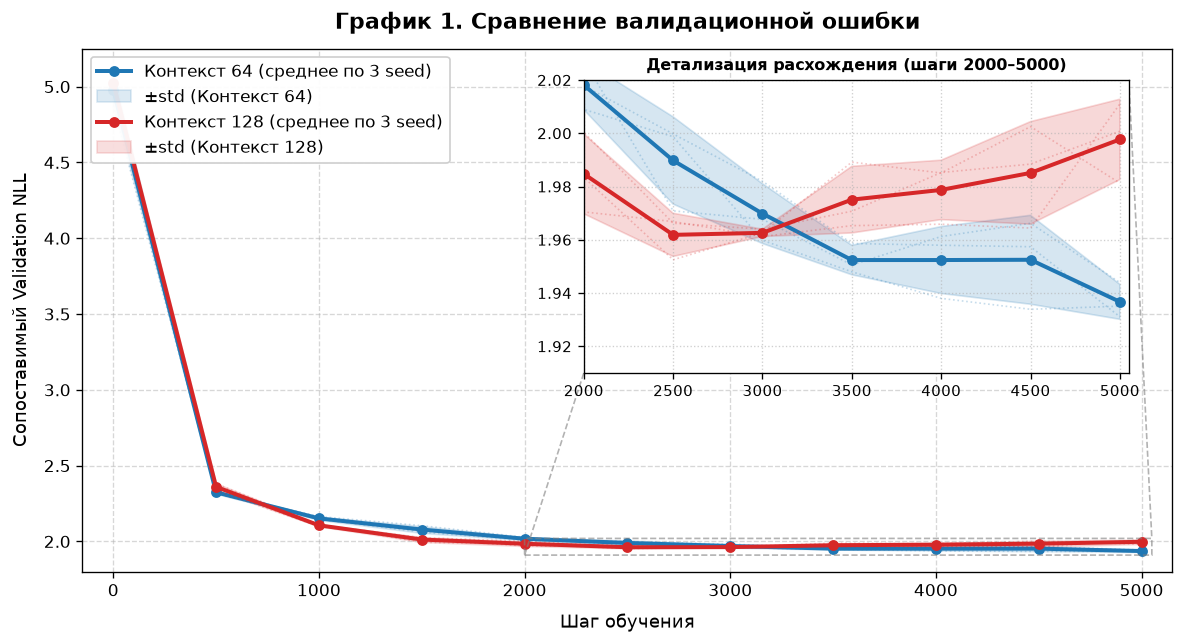

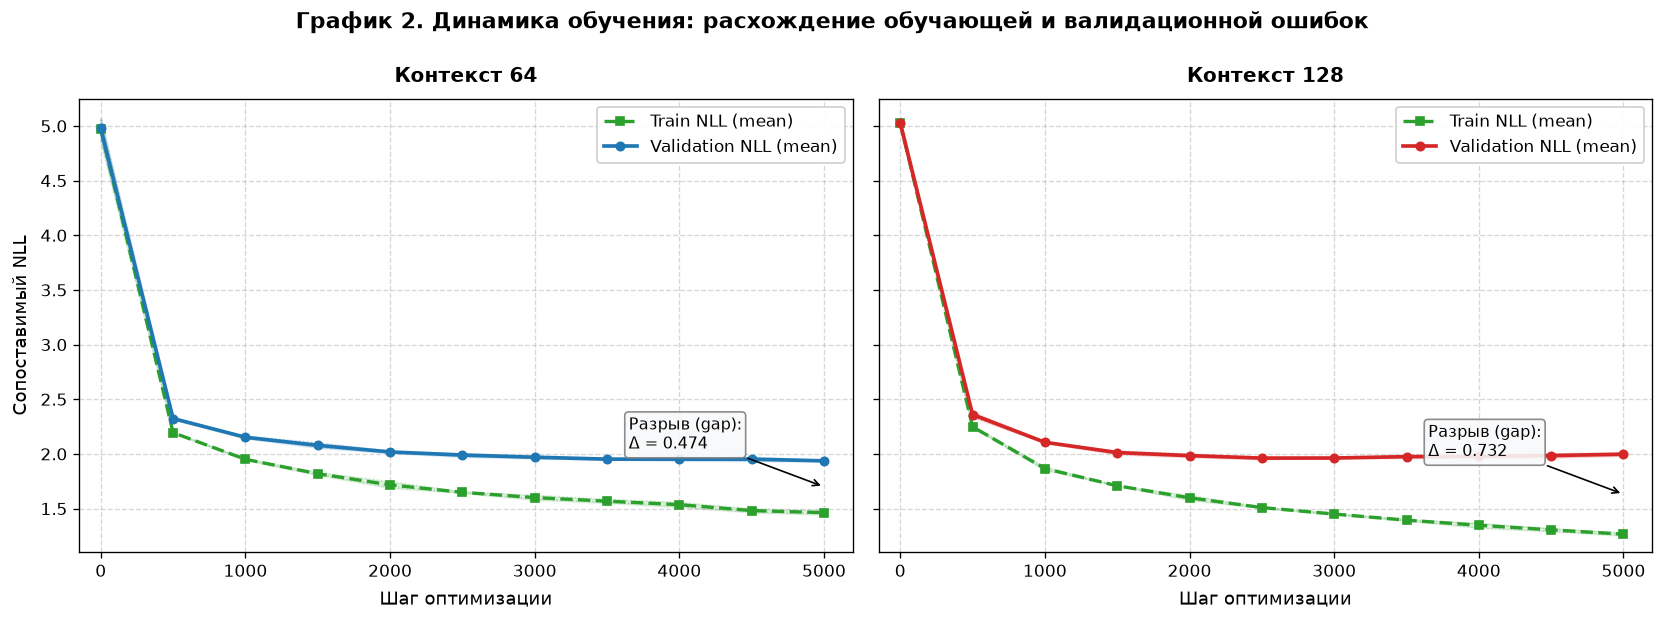

In [6]:
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})

steps = np.arange(0, 5001, 500)
c64 = "#1f77b4"
c128 = "#d62728"
train_col = "#2ca02c"

# ==============================================================================
# График 1: Сравнение валидационной ошибки
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(10, 5.5), dpi=120)

for bs, col, label in [(64, c64, "Контекст 64"), (128, c128, "Контекст 128")]:
    sub = trajectories_df[trajectories_df["block_size"] == bs]
    means = np.array([sub[sub["step"] == s]["val_nll_comp"].mean() for s in steps])
    stds = np.array([sub[sub["step"] == s]["val_nll_comp"].std(ddof=1) for s in steps])
    
    # Тонкие полупрозрачные линии отдельных сидов
    for seed in SEEDS:
        s_traj = sub[sub["seed"] == seed]
        ax1.plot(s_traj["step"], s_traj["val_nll_comp"], color=col, alpha=0.25, linewidth=1.0, linestyle=":")
    
    # Средняя кривая
    ax1.plot(steps, means, color=col, linewidth=2.4, marker="o", markersize=5.5, label=f"{label} (среднее по 3 seed)")
    # Полупрозрачная область ±std
    ax1.fill_between(steps, means - stds, means + stds, color=col, alpha=0.15, label=f"±std ({label})")

ax1.set_title("График 1. Сравнение валидационной ошибки", fontsize=13, fontweight="bold", pad=12)
ax1.set_xlabel("Шаг обучения", fontsize=11, labelpad=8)
ax1.set_ylabel("Сопоставимый Validation NLL", fontsize=11, labelpad=8)
ax1.set_xlim(-150, 5150)
ax1.set_ylim(1.80, 5.25)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper left", framealpha=0.95)

# Врезка с увеличенным масштабом на шагах 2000–5000 (зона расхождения и переобучения)
axins = ax1.inset_axes([0.46, 0.38, 0.50, 0.56])
for bs, col in [(64, c64), (128, c128)]:
    sub = trajectories_df[trajectories_df["block_size"] == bs]
    means = np.array([sub[sub["step"] == s]["val_nll_comp"].mean() for s in steps])
    stds = np.array([sub[sub["step"] == s]["val_nll_comp"].std(ddof=1) for s in steps])
    
    for seed in SEEDS:
        s_traj = sub[sub["seed"] == seed]
        axins.plot(s_traj["step"], s_traj["val_nll_comp"], color=col, alpha=0.25, linewidth=1.0, linestyle=":")
    axins.plot(steps, means, color=col, linewidth=2.4, marker="o", markersize=5.5)
    axins.fill_between(steps, means - stds, means + stds, color=col, alpha=0.18)

axins.set_xlim(2000, 5050)
axins.set_ylim(1.91, 2.02)
axins.set_title("Детализация расхождения (шаги 2000–5000)", fontsize=9.5, fontweight="bold", pad=6)
axins.grid(True, linestyle=":", alpha=0.6)
axins.tick_params(labelsize=9)
ax1.indicate_inset_zoom(axins, edgecolor="gray", alpha=0.6, linestyle="--")

plt.tight_layout()
fig1.savefig(results_dir / "plot1_val_comparison.png", dpi=130)
plt.show()

# ==============================================================================
# График 2: Динамика обучения (две панели рядом с одинаковой шкалой Y)
# ==============================================================================
fig2, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True, dpi=120)

configs = [
    (ax_left, 64, c64, "Контекст 64"),
    (ax_right, 128, c128, "Контекст 128"),
]

for ax, bs, col, title in configs:
    sub = trajectories_df[trajectories_df["block_size"] == bs]
    
    val_means = np.array([sub[sub["step"] == s]["val_nll_comp"].mean() for s in steps])
    val_stds = np.array([sub[sub["step"] == s]["val_nll_comp"].std(ddof=1) for s in steps])
    
    train_means = np.array([sub[sub["step"] == s]["train_nll_comp"].mean() for s in steps])
    train_stds = np.array([sub[sub["step"] == s]["train_nll_comp"].std(ddof=1) for s in steps])
    
    # Тонкие линии отдельных сидов
    for seed in SEEDS:
        s_traj = sub[sub["seed"] == seed]
        ax.plot(s_traj["step"], s_traj["train_nll_comp"], color=train_col, alpha=0.20, linewidth=0.9, linestyle=":")
        ax.plot(s_traj["step"], s_traj["val_nll_comp"], color=col, alpha=0.20, linewidth=0.9, linestyle=":")
    
    # Train NLL
    ax.plot(steps, train_means, color=train_col, linestyle="--", linewidth=2.0, marker="s", markersize=4.5, label="Train NLL (mean)")
    ax.fill_between(steps, train_means - train_stds, train_means + train_stds, color=train_col, alpha=0.12)
    
    # Validation NLL
    ax.plot(steps, val_means, color=col, linestyle="-", linewidth=2.2, marker="o", markersize=5, label="Validation NLL (mean)")
    ax.fill_between(steps, val_means - val_stds, val_means + val_stds, color=col, alpha=0.15)
    
    # Аннотация разрыва (generalization gap) на шаге 5000
    gap = val_means[-1] - train_means[-1]
    ax.annotate(
        f"Разрыв (gap):\nΔ = {gap:.3f}",
        xy=(5000, (val_means[-1] + train_means[-1]) / 2),
        xytext=(3650, (val_means[-1] + train_means[-1]) / 2 + 0.35),
        arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
        fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.25", fc="#f8f9fa", ec="gray", alpha=0.9),
    )

    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Шаг оптимизации", fontsize=11, labelpad=6)
    ax.set_xlim(-150, 5200)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", framealpha=0.95, fontsize=10)

ax_left.set_ylabel("Сопоставимый NLL", fontsize=11, labelpad=6)
ax_left.set_ylim(1.10, 5.25)

fig2.suptitle("График 2. Динамика обучения: расхождение обучающей и валидационной ошибок", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
fig2.savefig(results_dir / "plot2_train_val_dynamics.png", dpi=130)
plt.show()

## 5. Генерация текста

Качественное сравнение моделей после 5000 итераций обучения (финальные чекпоинты) при едином сиде обучения (`MODEL_SEED = 1337`) для обеих конфигураций (`block_size = 64` и `block_size = 128`). Параметры генерации и затравки можно свободно изменять в начале ячейки. Ячейка автономна и работает сразу после перезапуска ядра без предварительного выполнения других ячеек.

In [6]:
# ==============================================================================
# Параметры генерации (редактируемые)
# ==============================================================================
PROMPTS = [
    "Я помню ",
    "Когда ",
    "Любовь ",
]
MODEL_SEED = 1337
TEMPERATURE = 0.8
TOP_K = 40
MAX_NEW_TOKENS = 400
GENERATION_SEED = 42

# ==============================================================================
# Автономная загрузка финальных моделей (шаг 5000) и генерация
# ==============================================================================
from pathlib import Path
import torch
from gpt import get_device, load_corpus, load_checkpoint, validate_prompt

results_dir = Path("results/pushkin_seeds")
device = get_device() if "device" not in globals() else device

# Загрузка словаря корпуса, если не был загружен в память ранее
if "corpus" not in globals():
    corpus = load_corpus("input.txt", encoding="utf-8", train_ratio=0.9)

# Проверка наличия финальных чекпоинтов на шаге 5000
ckpt_path_64 = results_dir / f"checkpoint_64_seed{MODEL_SEED}_final.pt"
ckpt_path_128 = results_dir / f"checkpoint_128_seed{MODEL_SEED}_final.pt"

if not ckpt_path_64.exists():
    raise FileNotFoundError(
        f"Чекпоинт для block_size=64 не найден: {ckpt_path_64}. Проверьте доступность чекпоинтов для MODEL_SEED={MODEL_SEED}."
    )
if not ckpt_path_128.exists():
    raise FileNotFoundError(
        f"Чекпоинт для block_size=128 не найден: {ckpt_path_128}. Проверьте доступность чекпоинтов для MODEL_SEED={MODEL_SEED}."
    )

print(f"Устройство для генерации: {device}")
print(f"Загрузка финальных чекпоинтов (step=5000, seed={MODEL_SEED}):")
print(f" - Модель 64:  {ckpt_path_64.name}")
print(f" - Модель 128: {ckpt_path_128.name}\n")

chk64 = load_checkpoint(ckpt_path_64, device=device)
chk128 = load_checkpoint(ckpt_path_128, device=device)
model_64 = chk64["model"]
model_128 = chk128["model"]

# Проверка допустимости символов в затравках
for p in PROMPTS:
    valid, missing = validate_prompt(p, corpus["stoi"])
    if not valid:
        raise ValueError(f"ПРОМПТ '{p}' содержит недопустимые символы: {missing}")

# Генерация текста для каждой затравки
for prompt in PROMPTS:
    prompt_tensor = torch.tensor([corpus["encode"](prompt)], dtype=torch.long, device=device)
    print("=" * 80)
    print(f"ПРОМПТ: «{prompt}»  [T={TEMPERATURE}, top_k={TOP_K}, gen_seed={GENERATION_SEED}]")
    print("=" * 80)

    rng64 = torch.Generator(device=device if device == "cpu" else "cuda").manual_seed(GENERATION_SEED)
    out64 = model_64.generate(prompt_tensor, max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_k=TOP_K, generator=rng64)
    t64 = corpus["decode"](out64[0].tolist())

    rng128 = torch.Generator(device=device if device == "cpu" else "cuda").manual_seed(GENERATION_SEED)
    out128 = model_128.generate(prompt_tensor, max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_k=TOP_K, generator=rng128)
    t128 = corpus["decode"](out128[0].tolist())

    print(f"\n[Контекст 64 (seed={MODEL_SEED}, step=5000)]:\n{t64.strip()}\n")
    print(f"\n[Контекст 128 (seed={MODEL_SEED}, step=5000)]:\n{t128.strip()}\n")
    print("-" * 80)

Устройство для генерации: cuda
Загрузка финальных чекпоинтов (step=5000, seed=1337):
 - Модель 64:  checkpoint_64_seed1337_final.pt
 - Модель 128: checkpoint_128_seed1337_final.pt

ПРОМПТ: «Я помню »  [T=0.8, top_k=40, gen_seed=42]

[Контекст 64 (seed=1337, step=5000)]:
Я помню нашу не смелые глаза.

ПОСЛАНИЕ И ФОЛЬНИЕ К ОДУ)

Где кричаном - легкой волнах:
Меж ты, поспасен, и блеск упоенье,
Твой один сон почил
И недуг ввеселый в тишине
В последний свет, на тевере он воит;
Прошлых оков... но страшесь его.

Здесь минуты мне внемлет он вдруг...
Пыль мой друг, полуный мох
В угибель меня - говорит....
И в горь огнях слышах певцы
Вас я в ней мир... прости на печальных ваш
И па


[Контекст 128 (seed=1337, step=5000)]:
Я помню ночь не смею,
Не может быть меня внимал -
Как посмеял мне счастливый одинок.
Приди, следов, а за силось услышал
Пуглянусь из собою,
Как снего, ввеселья в тишине,
Душой умер воздух нас водосил
И брожу в тишине стучит,
И стальную дануть,
Чуть мы смело наклониться.

* * *



## 6. Выводы

По результатам серии из 6 независимых сессий обучения на трех случайных сидах (`SEEDS = [42, 1337, 2026]`) модель с длиной контекста 64 показала более низкую валидационную ошибку при 5000 шагах оптимизации: сопоставимый Validation NLL составил **$1.9367 \pm 0.0066$** для контекста 64 против **$1.9977 \pm 0.0151$** для контекста 128. Преимущество контекста 64 зафиксировано на всех трех сидах со средней парной разностью $\Delta = +0.0610 \pm 0.0173$. При этом шаг обучения контекста 128 требует в ~1.95 раза больше вычислительного времени ($96.3$ мс против $49.3$ мс), а суммарное время обучения возрастает с 4.1 до 8.0 минут.

Модель с расширенным контекстом 128 демонстрирует воспроизводимое на трех сидах переобучение: валидационная ошибка достигает локального минимума в районе 2500–3000 шагов (Val NLL $\approx 1.9593$), после чего начинает монотонно возрастать при продолжающемся снижении ошибки на обучении (Train NLL падает до $1.2660$, а разрыв между Train и Val NLL превышает 0.73). Увеличение длины контекста вдвое при неизменном объеме корпуса (~546 тыс. символов) и фиксированных параметрах регуляризации ускоряет запоминание обучающих последовательностей, тогда как более узкое окно внимания контекста 64 обеспечивает лучшую генерализацию.